### Project Title: Certificate Authenticity Detection using CNN

#### Overview:
This project aims to classify images of certificates as either 'Real' or 'Fake' using a Convolutional Neural Network (CNN) built with TensorFlow/Keras. The model will be trained on a custom dataset containing images of real and fake certificates. The process will involve data loading, preprocessing, model building, training, and evaluation.

In [24]:
# %% [code]
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [26]:
# %% [code]
import pandas as pd
import os
from sklearn.model_selection import train_test_split

# Define the base path from the kernel state
#dataset_path = '/content/drive/MyDrive/Pattern DATA SET/dataset'
dataset_path = '/content/drive/MyDrive/Pattern DATA SET/dataset' # Define dataset_path with the provided value
base_path = dataset_path # Using the variable from kernel state

# --- Step 1: Create metadata_df from folder structure ---
image_paths = []
labels = []

real_dir = os.path.join(base_path, 'real')
fake_dir = os.path.join(base_path, 'fake')

for filename in os.listdir(real_dir):
    if filename.endswith(('.jpg', '.jpeg', '.png')):
        image_paths.append(os.path.join(real_dir, filename))
        labels.append('Real')

for filename in os.listdir(fake_dir):
    if filename.endswith(('.jpg', '.jpeg', '.png')):
        image_paths.append(os.path.join(fake_dir, filename))
        labels.append('Fake')

metadata_df = pd.DataFrame({
    'filepath': image_paths,
    'class_label': labels
})

# Display initial metadata_df info
print("Original Dataset Distribution:")
display(metadata_df['class_label'].value_counts())

# --- Step 2: Perform a stratified train-validation split ---
# This ensures both classes are present in both train and validation sets
train_df, val_df = train_test_split(
    metadata_df,
    test_size=0.2, # 20% for validation
    stratify=metadata_df['class_label'], # Stratify by class_label to maintain class balance
    random_state=42 # for reproducibility
)

print("\nTraining Set Distribution:")
display(train_df['class_label'].value_counts())

print("\nValidation Set Distribution:")
display(val_df['class_label'].value_counts())

# Display the first few rows of the training dataframe
print("\nFirst 5 rows of Training Data:")
display(train_df.head())

Original Dataset Distribution:


,count
class_label,
Real,152
Fake,74



Training Set Distribution:


,count
class_label,
Real,121
Fake,59



Validation Set Distribution:


,count
class_label,
Real,31
Fake,15



First 5 rows of Training Data:


,filepath,class_label
31,/content/drive/MyDrive/Pattern DATA SET/datase...,Real
182,/content/drive/MyDrive/Pattern DATA SET/datase...,Fake
143,/content/drive/MyDrive/Pattern DATA SET/datase...,Real
39,/content/drive/MyDrive/Pattern DATA SET/datase...,Real
1,/content/drive/MyDrive/Pattern DATA SET/datase...,Real


In [27]:
# %% [code]
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Image dimensions and batch size
IMG_WIDTH = 128
IMG_HEIGHT = 128
TARGET_SIZE = (IMG_WIDTH, IMG_HEIGHT)
BATCH_SIZE = 32

# Initialize ImageDataGenerator with data augmentation and rescaling
# Note: validation_split is removed here as we are using train_df and val_df directly
datagen = ImageDataGenerator(
    rescale=1./255,            # Rescale pixel values to [0, 1]
    rotation_range=20,         # Randomly rotate images by up to 20 degrees
    horizontal_flip=True,      # Randomly flip images horizontally
    # You can add more augmentation if needed, e.g., zoom_range, width_shift_range, height_shift_range
)

# Create training generator from train_df
train_generator = datagen.flow_from_dataframe(
    dataframe=train_df, # Use the stratified training dataframe
    x_col='filepath',
    y_col='class_label',
    target_size=TARGET_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',       # For binary classification
    shuffle=True               # Shuffle data for training
)

# Create validation generator from val_df
# It's good practice to use a separate ImageDataGenerator for validation/test sets without augmentation
# to only apply rescaling, but for simplicity, we'll reuse the main datagen.
# However, it's crucial to set shuffle=False and not apply validation_split here.
validation_datagen = ImageDataGenerator(rescale=1./255) # Only rescaling for validation

validation_generator = validation_datagen.flow_from_dataframe(
    dataframe=val_df, # Use the stratified validation dataframe
    x_col='filepath',
    y_col='class_label',
    target_size=TARGET_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',       # For binary classification
    shuffle=False              # No need to shuffle validation data
)

print(f"Number of training samples: {train_generator.samples}")
print(f"Number of validation samples: {validation_generator.samples}")
print(f"Class indices: {train_generator.class_indices}")

Found 180 validated image filenames belonging to 2 classes.
Found 46 validated image filenames belonging to 2 classes.
Number of training samples: 180
Number of validation samples: 46
Class indices: {'Fake': 0, 'Real': 1}


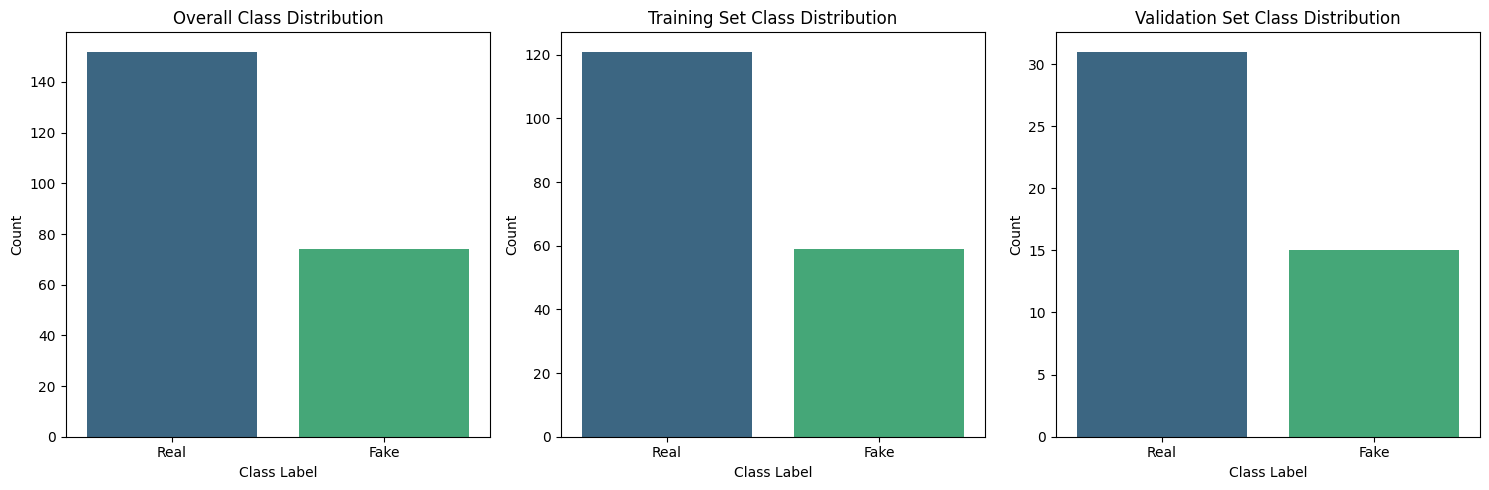

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 5))

# Overall Dataset Distribution
plt.subplot(1, 3, 1)
sns.countplot(x='class_label', data=metadata_df, palette='viridis', hue='class_label', legend=False)
plt.title('Overall Class Distribution')
plt.xlabel('Class Label')
plt.ylabel('Count')

# Training Set Distribution
plt.subplot(1, 3, 2)
sns.countplot(x='class_label', data=train_df, palette='viridis', hue='class_label', legend=False)
plt.title('Training Set Class Distribution')
plt.xlabel('Class Label')
plt.ylabel('Count')

# Validation Set Distribution
plt.subplot(1, 3, 3)
sns.countplot(x='class_label', data=val_df, palette='viridis', hue='class_label', legend=False)
plt.title('Validation Set Class Distribution')
plt.xlabel('Class Label')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input

# Build the custom CNN model
model = Sequential([
    # Input layer to define the input shape
    Input(shape=(IMG_WIDTH, IMG_HEIGHT, 3)),

    # First Conv2D + MaxPooling layer
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Second Conv2D + MaxPooling layer
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Third Conv2D + MaxPooling layer
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Flatten the output for the Dense layers
    Flatten(),

    # Dense layer with 128 units and ReLU activation
    Dense(128, activation='relu'),

    # Final Dense layer for binary classification with 1 unit and Sigmoid activation
    Dense(1, activation='sigmoid')
])

# Display model summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# %% [code]
from tensorflow.keras.optimizers import Adam

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=0.001), # Using Adam optimizer with a default learning rate
    loss='binary_crossentropy',       # Binary cross-entropy for binary classification
    metrics=['accuracy']              # Track accuracy during training
)

# Train the model
EPOCHS = 10
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // BATCH_SIZE
)

Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 23s 4s/step - accuracy: 0.4932 - loss: 0.9840 - val_accuracy: 0.6562 - val_loss: 0.6819
Epoch 2/10
1/5 ━━━━━━━━━━━━━━━━━━━━ 3s 942ms/step - accuracy: 0.5625 - loss: 0.6905

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 409ms/step - accuracy: 0.5625 - loss: 0.6905 - val_accuracy: 0.6562 - val_loss: 0.6743
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.6554 - loss: 0.6644 - val_accuracy: 0.6562 - val_loss: 0.6385
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 388ms/step - accuracy: 0.7500 - loss: 0.5856 - val_accuracy: 0.6562 - val_loss: 0.6797
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.6486 - loss: 0.6818 - val_accuracy: 0.6562 - val_loss: 0.6376
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 228ms/step - accuracy: 0.7812 - loss: 0.5887 - val_accuracy: 0.6562 - val_loss: 0.6376
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.6959 - loss: 0.6297 - val_accuracy: 0.6562 - val_loss: 0.6361
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 407ms/step - accuracy: 0.5625 - loss: 0.7394 - val_accuracy: 0.6562 - val_loss: 0.6351
Epoch 9/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.6486 - loss: 0.6607 - val_accuracy: 0.6562 - val_loss: 0.6350
Epoch 10/10

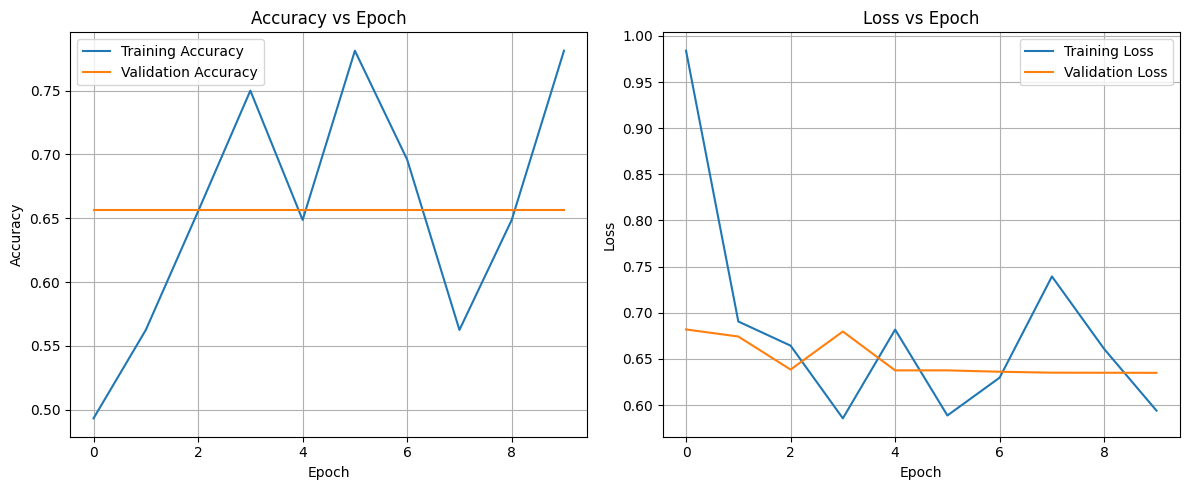

In [31]:
# %% [code]
import matplotlib.pyplot as plt

# Plot Accuracy vs Epoch
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss vs Epoch
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [32]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Get true labels and predictions for the validation set
# Ensure the validation generator is reset and used correctly for prediction
validation_generator.reset() # Reset generator to ensure proper order
y_pred_prob = model.predict(validation_generator, steps=validation_generator.samples // BATCH_SIZE + (1 if validation_generator.samples % BATCH_SIZE > 0 else 0))
y_pred_classes_eval = (y_pred_prob > 0.5).astype(int)

# Get true labels directly from the validation generator
y_true_eval = validation_generator.classes

# Confusion Matrix
cm = confusion_matrix(y_true_eval, y_pred_classes_eval)
print("Confusion Matrix:")
print(cm)

# Classification Report
# Need to map class indices back to original labels for the report
class_indices = train_generator.class_indices
# Determine the order of labels based on class_indices
idx_to_class = {v: k for k, v in class_indices.items()}
ordered_class_names = [idx_to_class[i] for i in sorted(idx_to_class.keys())]

# Extract numerical labels in the correct order for the 'labels' parameter
numerical_labels = sorted(class_indices.values())

cr = classification_report(y_true_eval, y_pred_classes_eval, labels=numerical_labels, target_names=ordered_class_names, zero_division=0)
print("\nClassification Report:")
print(cr)

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 224ms/step
Confusion Matrix:
[[ 0 15]
 [ 0 31]]

Classification Report:
              precision    recall  f1-score   support

        Fake       0.00      0.00      0.00        15
        Real       0.67      1.00      0.81        31

    accuracy                           0.67        46
   macro avg       0.34      0.50      0.40        46
weighted avg       0.45      0.67      0.54        46



In [33]:
# %% [code]
import plotly.express as px
import pandas as pd

# Assumption: 'cm' is your confusion matrix (2x2 for binary classification)
# and 'train_generator' or 'train_ds' defines class indices.

# Step 1: Map class indices to class labels
class_indices = train_generator.class_indices  # e.g., {'fake': 0, 'real': 1}
idx_to_class = {v: k for k, v in class_indices.items()}
class_labels = [idx_to_class[i] for i in sorted(idx_to_class.keys())]

# Step 2: Convert confusion matrix to DataFrame for Plotly
cm_df = pd.DataFrame(cm, index=class_labels, columns=class_labels)

# Step 3: Create interactive heatmap
fig = px.imshow(
    cm_df,
    labels=dict(x="Predicted Label", y="True Label", color="Count"),
    x=class_labels,
    y=class_labels,
    text_auto=True,
    color_continuous_scale="Blues"
)

# Step 4: Improve layout for readability
fig.update_xaxes(side="bottom")
fig.update_layout(
    title_text="<b>Confusion Matrix</b>",
    title_x=0.5,
    xaxis_title="Predicted Label",
    yaxis_title="True Label",
    template="plotly_white"
)

# Step 5: Show the figure
fig.show()

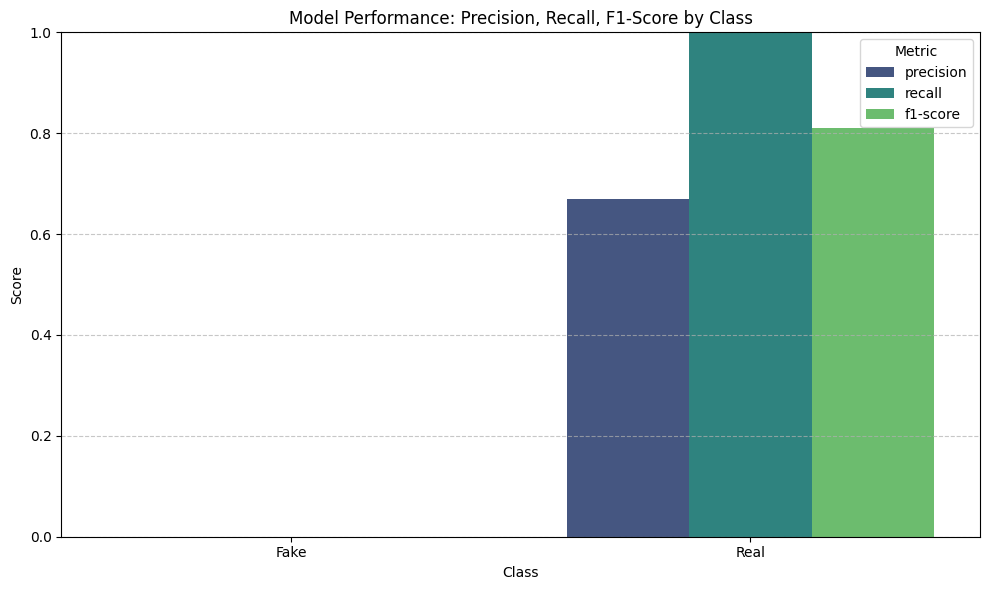

In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO

# Assuming 'cr' contains the classification report string
# Parse the classification report string into a DataFrame
# The classification report format has a header and then metrics for each class
cr_data = StringIO(cr)
report_df = pd.read_csv(cr_data, sep=r'\s{2,}', engine='python', index_col=0)

# Remove 'accuracy', 'macro avg', and 'weighted avg' rows for plotting class-specific metrics
report_df_filtered = report_df.drop(index=['accuracy', 'macro avg', 'weighted avg'], errors='ignore')

# Drop the 'support' column as it's not a performance metric for this plot
report_df_filtered = report_df_filtered.drop(columns=['support'], errors='ignore')

# Reshape the DataFrame for plotting
plot_df = report_df_filtered.stack().reset_index()
plot_df.columns = ['Class', 'Metric', 'Score']

# Create a grouped bar plot
plt.figure(figsize=(10, 6))
sns.barplot(data=plot_df, x='Class', y='Score', hue='Metric', palette='viridis')
plt.title('Model Performance: Precision, Recall, F1-Score by Class')
plt.ylabel('Score')
plt.ylim(0, 1) # Metrics are between 0 and 1
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

Found 15 misclassified 'Fake' images.


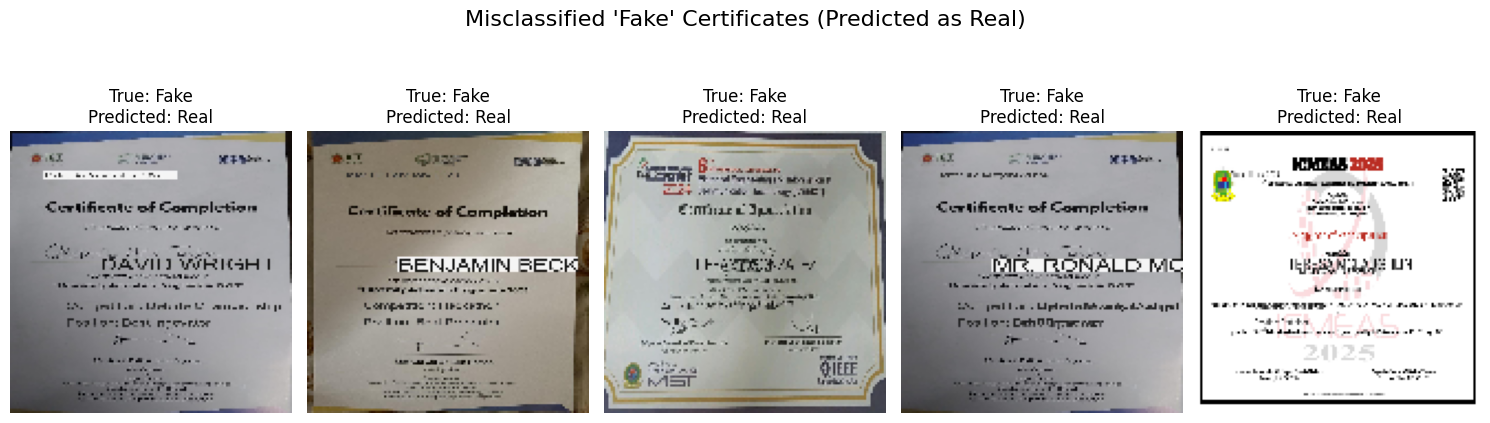

In [35]:
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing import image

# Assuming y_true_eval and y_pred_classes_eval are available from previous evaluation
# Also assuming val_df is available with filepaths in the same order

# Create a DataFrame to easily associate predictions with file paths and true labels
val_results_df = val_df.copy()
val_results_df['true_label_encoded'] = y_true_eval # Ensure this matches the generator's encoding (Fake:0, Real:1)
val_results_df['predicted_label_encoded'] = y_pred_classes_eval

# Filter for misclassified 'Fake' images (true_label = Fake (0), predicted_label = Real (1))
misclassified_fake_images_df = val_results_df[
    (val_results_df['true_label_encoded'] == 0) &
    (val_results_df['predicted_label_encoded'] == 1)
]

print(f"Found {len(misclassified_fake_images_df)} misclassified 'Fake' images.")

if not misclassified_fake_images_df.empty:
    # Display a few of the misclassified images
    num_images_to_display = min(5, len(misclassified_fake_images_df)) # Display up to 5 images

    plt.figure(figsize=(15, 5))
    plt.suptitle("Misclassified 'Fake' Certificates (Predicted as Real)", fontsize=16)

    for i, row in enumerate(misclassified_fake_images_df.head(num_images_to_display).itertuples()):
        filepath = row.filepath

        # Load and display image
        img = image.load_img(filepath, target_size=TARGET_SIZE)

        plt.subplot(1, num_images_to_display, i + 1)
        plt.imshow(img)
        plt.title(f"True: Fake\nPredicted: Real")
        plt.axis('off')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust layout to prevent title overlap
    plt.show()
else:
    print("No 'Fake' images were misclassified as 'Real'.")

In [36]:
# %% [code]
from tensorflow.keras.preprocessing import image

def predict_certificate(image_path):
    img = image.load_img(image_path, target_size=TARGET_SIZE)
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) # Create a batch
    img_array /= 255.0 # Rescale as done during training

    prediction = model.predict(img_array)[0][0]

    # Assuming 0 is 'Fake' and 1 is 'Real' based on train_generator.class_indices
    # Verify this with train_generator.class_indices if needed
    class_indices = train_generator.class_indices
    label_map = {v: k for k, v in class_indices.items()}

    if prediction > 0.5:
        label = label_map[1] # Real
        confidence = prediction * 100
    else:
        label = label_map[0] # Fake
        confidence = (1 - prediction) * 100

    return label, confidence

# Example usage:
# Choose a random image from the dataset for testing

# Get a random real image path
real_image_example = metadata_df[metadata_df['class_label'] == 'Real'].sample(1)['filepath'].iloc[0]
print(f"Predicting for a 'Real' image: {real_image_example}")
label, confidence = predict_certificate(real_image_example)
print(f"Prediction: {label} with {confidence:.2f}% confidence")

print("\n" + "-"*30 + "\n")

# Get a random fake image path
fake_image_example = metadata_df[metadata_df['class_label'] == 'Fake'].sample(1)['filepath'].iloc[0]
print(f"Predicting for a 'Fake' image: {fake_image_example}")
label, confidence = predict_certificate(fake_image_example)
print(f"Prediction: {label} with {confidence:.2f}% confidence")

Predicting for a 'Real' image: /content/drive/MyDrive/Pattern DATA SET/dataset/real/real_086.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
Prediction: Real with 61.45% confidence

------------------------------

Predicting for a 'Fake' image: /content/drive/MyDrive/Pattern DATA SET/dataset/fake/fake_064.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
Prediction: Real with 62.84% confidence


In [37]:
# %% [code]
from google.colab import files
import io

print("Please upload an image from your PC:")
uploaded = files.upload()

# Get the path of the first uploaded image
# Usually only one file is uploaded, so we take the first key
for filename in uploaded.keys():
    uploaded_image_path = filename
    print(f"Uploaded image path: {uploaded_image_path}")
    break  # Exit the loop after getting the first file

# Use the uploaded image for prediction
if 'uploaded_image_path' in locals():
    predicted_label, confidence_score = predict_certificate(uploaded_image_path)

    print(f"\nUploaded Image: {uploaded_image_path}")
    print(f"Model Prediction: {predicted_label} (Confidence: {confidence_score:.2f}%)")
else:
    print("No image was uploaded.")

Please upload an image from your PC:


Saving Screenshot 2026-04-02 222840.png to Screenshot 2026-04-02 222840.png
Uploaded image path: Screenshot 2026-04-02 222840.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step

Uploaded Image: Screenshot 2026-04-02 222840.png
Model Prediction: Real (Confidence: 63.53%)
